# 1 · The game and its exact answers

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/Qubic_Zero/blob/main/notebooks/01_the_game_and_exact_answers.ipynb)

Qubic is tic-tac-toe on a 4 × 4 × 4 board: two players take turns claiming a cell, and the first to
own four cells in a line wins. It has 64 cells and at most 3<sup>64</sup> ≈ 3.4 × 10<sup>30</sup>
ways to fill them, so a table of its positions is out of the question. It has also been solved: the
first player wins (Patashnik, 1980; solved again by Allis and Schoo, 1992). That makes it a good
target for a learner. The goal is known, and how close a learner comes to it can be measured.

This notebook builds what the learner will be measured with, before any learning happens:

* **the game**, written so that ordinary tic-tac-toe and its 3 × 3 × 3 cousin run the very same code;
* **two players that need no training**, one random and one that follows two rules;
* **exact answers**: every position of tic-tac-toe, any position of the 3 × 3 × 3 game, and on
  Qubic the positions that can be won by force.

It needs NumPy only and runs in about a minute. The sentences that quote numbers are produced by the
code, so they stay in step with the run.

In [1]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("Qubic_Zero"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/Qubic_Zero"], check=True)
    sys.path.insert(0, os.path.abspath("Qubic_Zero/src"))

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import qubic_zero as qz
from qubic_zero import plotting as qp
from qubic_zero.evaluate import TacticsSuite, solved_sample, table_score

qp.use_style()
pd.options.display.float_format = "{:,.3f}".format
notebook_start = time.perf_counter()
games = {name: qz.game_by_name(name) for name in ("3x3", "3x3x3", "4x4x4")}
qubic = games["4x4x4"]

## One game, three boards

A game of this family is fully described by a table that says which cells lie on which line.
`LineGame.grid(n, dim)` writes that table for a board with `n` cells along each of `dim` axes
and every straight line of `n` cells on it. Everything else in the package is written against
the table: the rules, the symmetries, the exact searches, the network and the tree search.
The small boards are therefore not toy copies of Qubic. They exercise the same code, and on
them the right answers are known in full.

In [3]:
def kinds_of_lines(game):
    """How many lines run along an axis, across a square, and through the cube."""
    cells = np.array(np.unravel_index(game.lines, game.shape))   # (dim, lines, k)
    changing = (cells[:, :, 0] != cells[:, :, 1]).sum(axis=0)       # coordinates that change along each line
    return [int((changing == d).sum()) for d in (1, 2, 3)]

rows = {}
for name, game in games.items():
    along, across, through = kinds_of_lines(game)
    rows[name.replace("x", " × ")] = {
        "cells": game.n_cells, "lines": game.n_lines, "cells per line": game.k,
        "lines along an axis": along, "diagonals of a square": across, "diagonals of the cube": through,
        "lines through a cell": f"{game.degree.min()} to {game.degree.max()}",
        "symmetries": len(game.symmetries),
        "ways to fill the board": f"{3.0 ** game.n_cells:.1e}",
    }
boards = pd.DataFrame(rows).T
along, across, through = kinds_of_lines(qubic)
rich = np.flatnonzero(qubic.degree == qubic.degree.max())
display(Markdown(
    f"Qubic has **{qubic.n_cells} cells and {qubic.n_lines} lines**: {along} run along an axis, {across} are diagonals of a "
    f"4 × 4 square, and {through} are the diagonals of the cube. {len(rich)} cells lie on {qubic.degree.max()} lines each "
    f"(the 8 corners and the 8 cells of the inner 2 × 2 × 2 cube); the other {qubic.n_cells - len(rich)} lie on {qubic.degree.min()}."
))
boards

Qubic has **64 cells and 76 lines**: 48 run along an axis, 24 are diagonals of a 4 × 4 square, and 4 are the diagonals of the cube. 16 cells lie on 7 lines each (the 8 corners and the 8 cells of the inner 2 × 2 × 2 cube); the other 48 lie on 4.

,cells,lines,cells per line,lines along an axis,diagonals of a square,diagonals of the cube,lines through a cell,symmetries,ways to fill the board
3 × 3,9,8,3,6,2,0,2 to 4,8,2.0e+04
3 × 3 × 3,27,49,3,27,18,4,4 to 13,48,7.6e+12
4 × 4 × 4,64,76,4,48,24,4,4 to 7,192,3.4e+30


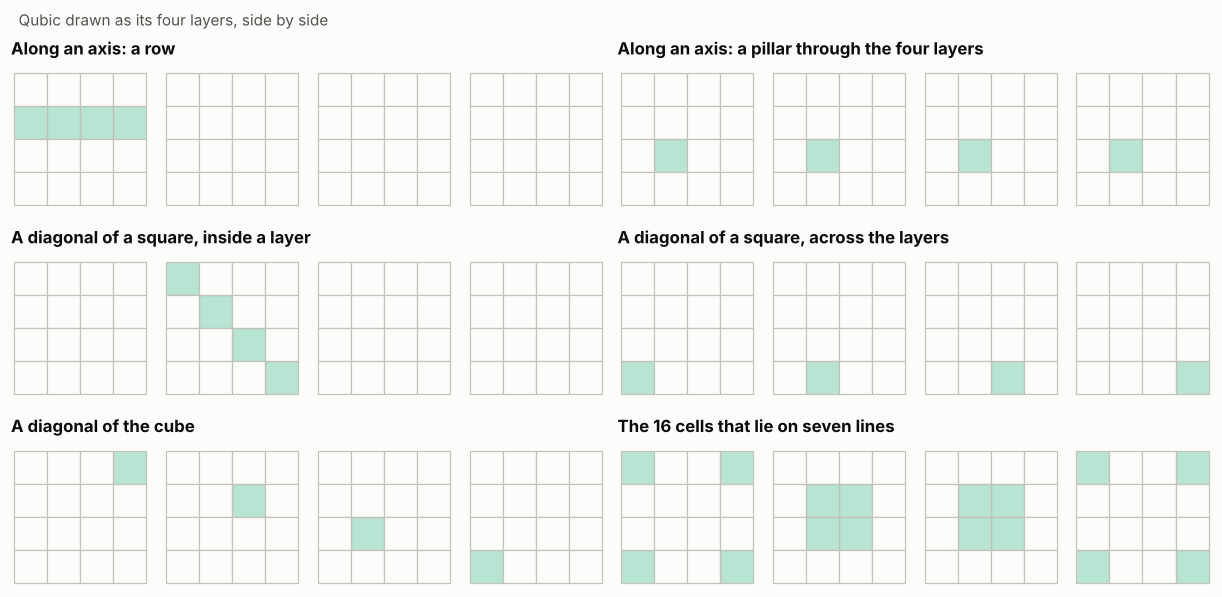

In [4]:
cell = lambda x, y, z: 16 * x + 4 * y + z   # layer, row, column
examples = {
    "Along an axis: a row": [cell(0, 1, j) for j in range(4)],
    "Along an axis: a pillar through the four layers": [cell(j, 2, 1) for j in range(4)],
    "A diagonal of a square, inside a layer": [cell(1, j, j) for j in range(4)],
    "A diagonal of a square, across the layers": [cell(j, 3, j) for j in range(4)],
    "A diagonal of the cube": [cell(j, j, 3 - j) for j in range(4)],
    f"The {len(rich)} cells that lie on seven lines": rich,
}
fig, axes = plt.subplots(3, 2, figsize=(11, 5.4))
for ax, (title, cells_) in zip(axes.ravel(), examples.items()):
    qp.draw_board(qubic, ax=ax, highlight=cells_, title=title)
fig.suptitle("Qubic drawn as its four layers, side by side", x=0.01, ha="left", fontsize=10, color=qp.INK_SECONDARY)
qp.savefig(fig, "01_lines_of_qubic");

## Symmetries, found from the lines alone

A symmetry of the game is a relabelling of the cells that maps every line onto a line. A
position and its image under a symmetry are the same position in all that matters, which is
worth a great deal to a learner: whatever it learns about one, it should know about the other.

`game.symmetries` finds them by exhaustive search from the table of lines. Nothing about the
geometry of the board is assumed, and so the search also finds the symmetries that are not
geometric.

The search finds **192 symmetries** of Qubic. The 48 rotations and reflections of the cube are all among them (True), which leaves a factor of 4 that no rigid motion explains. Under the full set the cells fall into 2 classes, of 16 and 48 cells: every cell on seven lines is equivalent to every other, and so is every cell on four. Tic-tac-toe has 8 symmetries and the 3 × 3 × 3 game 48, all of them geometric.

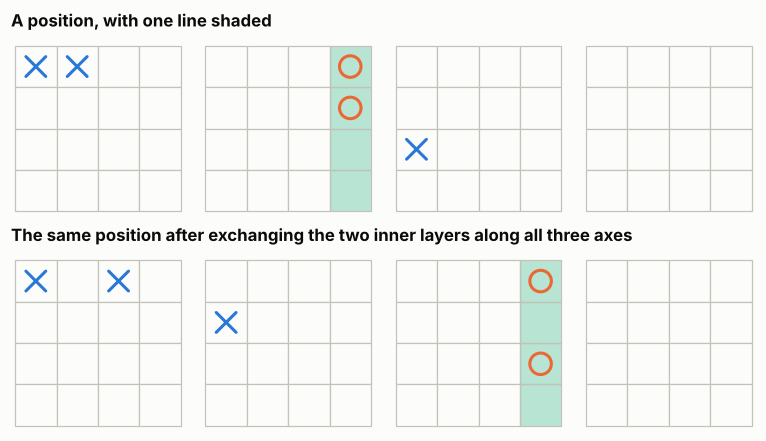

In [5]:
import itertools

coordinates = np.array(list(itertools.product(range(4), repeat=3)))
geometric = set()
for axes_ in itertools.permutations(range(3)):
    for flips in itertools.product((False, True), repeat=3):
        moved = coordinates[:, list(axes_)].copy()
        for a, flip in enumerate(flips):
            if flip:
                moved[:, a] = 3 - moved[:, a]
        geometric.add(tuple(np.ravel_multi_index(moved.T, (4, 4, 4)).tolist()))
found = {tuple(p) for p in qubic.symmetries.tolist()}

def orbits(game):
    sizes, seen = [], set()
    for c in range(game.n_cells):
        if c not in seen:
            orbit = set(game.symmetries[:, c].tolist())
            seen |= orbit
            sizes.append(len(orbit))
    return sorted(sizes)

swap = np.array([0, 2, 1, 3])                                     # exchange the two inner layers, along every axis
inner_swap = np.ravel_multi_index(swap[coordinates].T, (4, 4, 4))
display(Markdown(
    f"The search finds **{len(found)} symmetries** of Qubic. The {len(geometric)} rotations and reflections of the cube are all "
    f"among them ({geometric <= found}), which leaves a factor of {len(found) // len(geometric)} that no rigid motion explains. "
    f"Under the full set the cells fall into {len(orbits(qubic))} classes, of {' and '.join(map(str, orbits(qubic)))} cells: "
    f"every cell on seven lines is equivalent to every other, and so is every cell on four. "
    f"Tic-tac-toe has {len(games['3x3'].symmetries)} symmetries and the 3 × 3 × 3 game {len(games['3x3x3'].symmetries)}, "
    f"all of them geometric."
))

position = qubic.empty()
position[[cell(0, 0, 0), cell(0, 0, 1), cell(2, 2, 0)]] = 1
position[[cell(1, 0, 3), cell(1, 1, 3)]] = -1
line = [cell(1, j, 3) for j in range(4)]
image = position[inner_swap]                                     # the same position after the relabelling
image_line = [c for c in range(64) if inner_swap[c] in line]
fig, axes = plt.subplots(2, 1, figsize=(8.2, 3.9))
qp.draw_board(qubic, position, ax=axes[0], highlight=line, title="A position, with one line shaded")
qp.draw_board(qubic, image, ax=axes[1], highlight=image_line,
              title="The same position after exchanging the two inner layers along all three axes")
qp.savefig(fig, "01_inner_swap");

The lower drawing is the upper one with layers 2 and 3 exchanged, and rows 2 and 3, and columns
2 and 3. The shaded line is still a line, and so is every other line: nothing about the game
has changed. But the two crosses that were side by side are now a cell apart, and the two rings
are no longer in neighbouring rows. **Which cells are neighbours is not a fact about the game.**
Only which cells share a line is.

This matters for the choice of network. A convolution, the building block of AlphaZero's
network, treats neighbouring cells as related. That is right for Go. Here it bakes in a notion
that three quarters of the symmetries do not respect. The network used in this project passes
messages between cells and lines instead, and so has all 192 symmetries built in
(notebook 2 tests that claim, and notebook 3 compares the two networks).

## Two players that need no training

Every learner needs opponents whose strength does not depend on learning:

* the **random player** picks any empty cell;
* the **rule player** wins if it can (it completes a line of its own), blocks if it must (it
  takes the cell with which the opponent would complete a line), and otherwise picks any
  empty cell.

In [6]:
N_GAMES = 2_000
rng = np.random.default_rng(0)
pairings = [("random", "random"), ("rule", "random"), ("random", "rule"), ("rule", "rule")]
players = {"random": qz.random_player, "rule": qz.rule_player}
rows = []
for name, game in games.items():
    for first, second in pairings:
        result = qz.play_games(game, players[first], players[second], N_GAMES, rng)
        rows.append({"board": name.replace("x", " × "), "moves first": first, "moves second": second,
                     "first player wins": result.first_wins / N_GAMES, "draw": result.draws / N_GAMES,
                     "second player wins": result.second_wins / N_GAMES, "moves per game": result.plies.mean()})
baseline = pd.DataFrame(rows).set_index(["board", "moves first", "moves second"])
q = baseline.loc["4 × 4 × 4"]
display(Markdown(
    f"{N_GAMES:,} games for each pairing. On Qubic the rule player beats the random player in "
    f"**{q.loc[('rule', 'random'), 'first player wins']:.1%}** of the games it starts and in "
    f"{q.loc[('random', 'rule'), 'second player wins']:.1%} of those it does not. Between two random players the first move "
    f"is worth little: {q.loc[('random', 'random'), 'first player wins']:.1%} against {q.loc[('random', 'random'), 'second player wins']:.1%}. "
    f"Between two rule players it is {q.loc[('rule', 'rule'), 'first player wins']:.1%} against "
    f"{q.loc[('rule', 'rule'), 'second player wins']:.1%}, with {q.loc[('rule', 'rule'), 'draw']:.1%} drawn. "
    f"A perfect first player would win every game."
))
baseline.style.format({"first player wins": "{:.1%}", "draw": "{:.1%}", "second player wins": "{:.1%}", "moves per game": "{:.1f}"})

2,000 games for each pairing. On Qubic the rule player beats the random player in **99.8%** of the games it starts and in 99.9% of those it does not. Between two random players the first move is worth little: 51.4% against 48.5%. Between two rule players it is 49.5% against 45.3%, with 5.2% drawn. A perfect first player would win every game.

Stage (a) of the project's goal is to beat these two players essentially always. The table
shows why that alone says little: the rule player already beats the random one almost always,
and it is a long way from perfect.

## Exact answers

### Tic-tac-toe: every position

`solve_table` works out the value of every position that can arise from the empty board, by
exhaustive search.

In [7]:
ttt = games["3x3"]
start = time.perf_counter()
table = qz.solve_table(ttt)
table_seconds = time.perf_counter() - start
decided = table.outcome[table.decision]
ended = ttt.winner(table.boards[table.terminal])
scores = {name: table_score(table, player, np.random.default_rng(1)) for name, player in players.items()}
display(Markdown(
    f"Tic-tac-toe has **{len(table.boards):,} positions**, found and solved in {table_seconds:.2f} s. "
    f"{int(table.terminal.sum())} of them are finished games ({int((ended == 1).sum())} won by the first player, "
    f"{int((ended == -1).sum())} by the second, {int((ended == 0).sum())} drawn). In the other "
    f"**{int(table.decision.sum()):,}** there is a move to make: {int((decided == 1).sum()):,} are won for the player to move, "
    f"{int((decided == 0).sum()):,} drawn and {int((decided == -1).sum()):,} lost. The empty board is a "
    f"{'draw' if table.value[0] == 0 else 'win'}, and {int(table.best[0].sum())} of its 9 moves keep it one.\n\n"
    f"A player can now be scored on all {int(table.decision.sum()):,} positions at once, by whether its move keeps the value "
    f"of the position. The random player gives value away in **{scores['random']['mistakes']:,}** of them, the rule player "
    f"in **{scores['rule']['mistakes']:,}**; a perfect player in none. This count is the yardstick of notebook 2."
))

Tic-tac-toe has **5,478 positions**, found and solved in 0.03 s. 958 of them are finished games (626 won by the first player, 316 by the second, 16 drawn). In the other **4,520** there is a move to make: 2,836 are won for the player to move, 1,052 drawn and 632 lost. The empty board is a draw, and 9 of its 9 moves keep it one.

A player can now be scored on all 4,520 positions at once, by whether its move keeps the value of the position. The random player gives value away in **1,894** of them, the rule player in **265**; a perfect player in none. This count is the yardstick of notebook 2.

### The 3 × 3 × 3 game: any position

With 27 cells there are too many positions to list, but the game is so sharp that the value of
any one position can be found by searching to the end of the game (`solve`). The game cannot
end in a draw, and it is a win for the first player, like Qubic. That makes it the dress
rehearsal for the claim the project is after: *a player that wins every game it starts*.

`check_wins_every_game` turns that claim into a finite check. It follows the player's own move
in every position and tries **every** reply of the opponent, treating positions that differ by
a symmetry as one. A player here is a function that is handed a batch of positions and answers
with a move for each.

In [8]:
cube = games["3x3x3"]
solved = {}
start = time.perf_counter()
value = qz.solve(cube, cube.empty(), table=solved)
solve_seconds = time.perf_counter() - start

def perfect(game, boards, rng=None):
    """Any move after which the opponent is lost."""
    moves = []
    for board in boards:
        for move in np.flatnonzero(board == 0):
            after = game.play(board, move)
            if game.winner(after) != 0 or qz.solve(game, after, table=solved) == -1:
                moves.append(move)
                break
    return np.array(moves)

def first_empty(game, boards, rng=None):
    return (boards == 0).argmax(axis=1)

start = time.perf_counter()
walk = qz.check_wins_every_game(cube, perfect, threats="off")
walk_seconds = time.perf_counter() - start
careless = qz.check_wins_every_game(cube, first_empty, threats="off")
sample = solved_sample(cube, n=1500, seed=12345)
sample_scores = {name: table_score(sample, player, np.random.default_rng(1)) for name, player in players.items()}
display(Markdown(
    f"The empty 3 × 3 × 3 board is a **{'win' if value == 1 else 'draw or loss'} for the first player** "
    f"(searched to the end in {solve_seconds * 1000:.0f} ms).\n\n"
    f"A player that always picks a move after which the opponent is lost passes the exhaustive check: "
    f"**proven = {walk.proven}**, after {walk.decisions:,} positions in which it had to choose, {walk.wins:,} lines of play "
    f"that ended with its line on the board, and none that ended otherwise ({walk_seconds:.1f} s). "
    f"A player that takes the first empty cell fails it at once: the check returns a game it did not win "
    f"(*{careless.failures[0][1]}*).\n\n"
    f"For scoring single moves there is a sample of {len(sample.boards):,} positions from games between the two reference "
    f"players, each solved exactly ({int((sample.outcome == 1).sum()):,} won for the player to move, "
    f"{int((sample.outcome == -1).sum())} lost). The random player gives a win away in "
    f"{sample_scores['random']['mistakes']} of them and the rule player in {sample_scores['rule']['mistakes']}."
))

The empty 3 × 3 × 3 board is a **win for the first player** (searched to the end in 1 ms).

A player that always picks a move after which the opponent is lost passes the exhaustive check: **proven = True**, after 55,447 positions in which it had to choose, 51,070 lines of play that ended with its line on the board, and none that ended otherwise (2.3 s). A player that takes the first empty cell fails it at once: the check returns a game it did not win (*the opponent completed a line*).

For scoring single moves there is a sample of 1,500 positions from games between the two reference players, each solved exactly (1,063 won for the player to move, 437 lost). The random player gives a win away in 739 of them and the rule player in 296.

### Qubic: wins by force

Neither of these is possible on Qubic. What does carry over is the search for a win **by
force**: a chain of moves that each threaten to complete a line, so that the opponent has one
reply every time (the block), ending in a move that threatens twice. `threat_search` finds
such chains. When it reports a win, the win is certain. When it reports none, there may still be
a win that starts with a quiet move. Both published solutions of Qubic are built on a search of
this kind, with the quiet "strategic" moves chosen by hand (Patashnik) or by proof-number
search (Allis).

How often is a Qubic position won by force? Below, positions are taken from games in which
each move is the rule player's with probability 0.7 and random otherwise.

After 16 moves of such a game, **84%** of the positions are won by force for the player to move, and in 6% a line can be completed at once: the rest are wins that the rule player does not see. The search looked at 1 positions for a typical start (median) and 2,000 at most, 0.12 ms per start on average, and it never ran into its limit (0% incomplete).

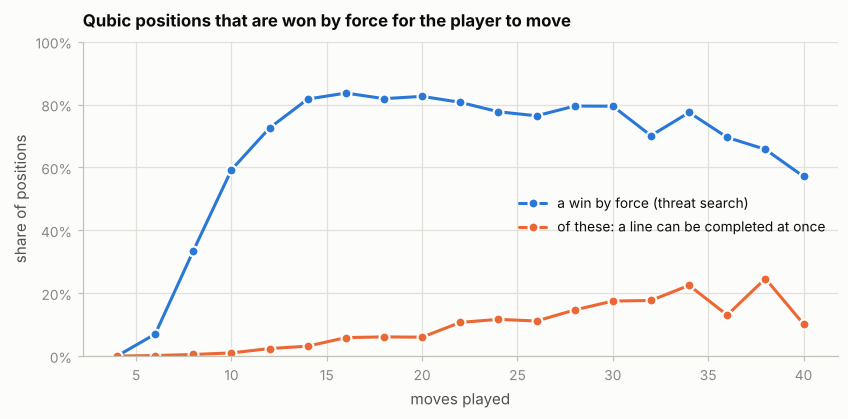

In [9]:
from qubic_zero.evaluate import _mixed_player
from qubic_zero.players import completing_cells

rng = np.random.default_rng(2)
boards = qubic.empty(600)
rows, nodes, seconds = [], [], 0.0
for ply in range(0, 41):
    boards = boards[~qubic.finished(boards)]
    if ply >= 4 and ply % 2 == 0:
        at_once = completing_cells(qubic, boards, qubic.to_move(boards)).any(axis=1)
        start = time.perf_counter()
        results = [qz.threat_search(qubic, b) for b in boards]
        seconds += time.perf_counter() - start
        nodes += [r.nodes for r in results]
        forced = np.array([r.win for r in results])
        rows.append({"moves played": ply, "positions": len(boards), "can complete a line at once": at_once.mean(),
                     "can force a win": forced.mean(), "search incomplete": np.mean([not r.complete for r in results])})
    boards = qubic.play(boards, _mixed_player(qubic, boards, rng))
by_ply = pd.DataFrame(rows).set_index("moves played")

fig, ax = plt.subplots(figsize=(7.6, 3.7))
ax.plot(by_ply.index, by_ply["can force a win"], color=qp.SERIES[0], marker="o", label="a win by force (threat search)")
ax.plot(by_ply.index, by_ply["can complete a line at once"], color=qp.SERIES[1], marker="o", label="of these: a line can be completed at once")
ax.set(xlabel="moves played", ylabel="share of positions", ylim=(0, 1), title="Qubic positions that are won by force for the player to move")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.45))
qp.savefig(fig, "01_forced_wins")

peak = by_ply["can force a win"].idxmax()
display(Markdown(
    f"After {peak} moves of such a game, **{by_ply.loc[peak, 'can force a win']:.0%}** of the positions are won by force for "
    f"the player to move, and in {by_ply.loc[peak, 'can complete a line at once']:.0%} a line can be completed at once: "
    f"the rest are wins that the rule player does not see. The search looked at {int(np.median(nodes))} positions for a typical "
    f"start (median) and {max(nodes):,} at most, {1000 * seconds / len(nodes):.2f} ms per start on average, and it never ran into "
    f"its limit ({by_ply['search incomplete'].max():.0%} incomplete)."
))

A good part of all positions in careless games are already decided, and the decision is hidden
several forced moves deep. These positions are where exact answers on Qubic come from.
`TacticsSuite` collects three kinds, distinct up to symmetry:

* **win**: the player to move can complete a line. Right: any cell that does.
* **block**: the opponent threatens to complete a line and the player to move cannot win first.
  Right: the one cell that stops it. Every other move loses at once.
* **force**: no line can be completed yet, but a win can be forced. Right: any first move of a
  forced win that the threat search can prove. Other moves may win more slowly, so the share of
  right moves here is a lower bound on the share of winning moves.

In [10]:
suite = TacticsSuite.build(qubic, per_kind=200, seed=12345)
rng = np.random.default_rng(3)
tactics = pd.DataFrame({name: suite.score(player, rng) for name, player in players.items()}).T
tactics.index.name = "player"
right_moves = suite.right["force"].sum(axis=1)
empty_cells = (suite.boards["force"] == 0).sum(axis=1)
display(Markdown(
    f"{suite!r}. The rule player solves the first two kinds by definition and finds a proven forcing move in "
    f"**{tactics.loc['rule', 'force']:.0%}** of the third, which is what picking at random gives "
    f"({tactics.loc['random', 'force']:.0%}; a 'force' position has {right_moves.mean():.1f} proven moves among "
    f"{empty_cells.mean():.0f} empty cells on average). A player that has learned Qubic's tactics should approach 100% on all three."
))
tactics.style.format("{:.1%}")

TacticsSuite(200 win, 200 block, 200 force on 4x4x4). The rule player solves the first two kinds by definition and finds a proven forcing move in **7%** of the third, which is what picking at random gives (10%; a 'force' position has 4.4 proven moves among 53 empty cells on average). A player that has learned Qubic's tactics should approach 100% on all three.

,win,block,force
player,,,
random,4.5%,3.0%,10.5%
rule,100.0%,100.0%,7.0%


## What is known, and what is not

| | Exact answers available | Used for |
|---|---|---|
| Tic-tac-toe | the value of every position and every move | scoring a learner on all 4,520 positions with a move to make |
| 3 × 3 × 3 | the value of any position, by search to the end; the exhaustive "wins every game it starts" check | scoring moves on a solved sample; rehearsing the check |
| Qubic | wins by force, where the threat search finds them | the tactics suite; closing branches of the exhaustive check |

Not reproduced here: the proof that Qubic is a win for the first player. Nothing in this
notebook shows it. It is taken from the literature, and re-deriving it with the learned
player's moves is the last stage of the project.

**References.** O. Patashnik, "Qubic: 4 × 4 × 4 tic-tac-toe", *Mathematics Magazine* 53, 1980.
L. V. Allis and P. N. A. Schoo, "Qubic solved again", in *Heuristic Programming in Artificial
Intelligence 3*, 1992. L. V. Allis, *Searching for Solutions in Games and Artificial
Intelligence*, PhD thesis, University of Limburg, 1994 (chapter 4).

Next: [notebook 2](02_small_games.ipynb) puts the whole learning pipeline through the two
small games. Back to the [overview](../README.md).

In [11]:
print(f"notebook ran in {time.perf_counter() - notebook_start:.0f} s")

notebook ran in 8 s
